In [1]:
# Import essential libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load file 
df=pd.read_csv("C:/indan-startup-ecosystem/00_Data/cleaned_date/cleaned_startup_funding.csv")
df.head()

,Sr No,Date,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,Investment Type,Amount
0,1,2020-01-09,BYJU’S,Technology & Software,E-learning,Bangalore,Tiger Global Management,Private Equity,3.076923e+06
1,2,2020-01-13,Shuttl,Transportation & Logistics,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,1.238214e+05
2,3,2020-01-09,Mamaearth,Retail & E-commerce,Retailer of baby and toddler products,Bangalore,Sequoia Capital India,Series B,2.824440e+05
3,4,2020-01-02,https://www.wealthbucket.in/,Financial Services & FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-Series A,4.615385e+04
4,5,2020-01-02,Fashor,"Fashion, Beauty & Lifestyle",Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed,2.769231e+04


#### Q1: Show the distribution of total funding amount.

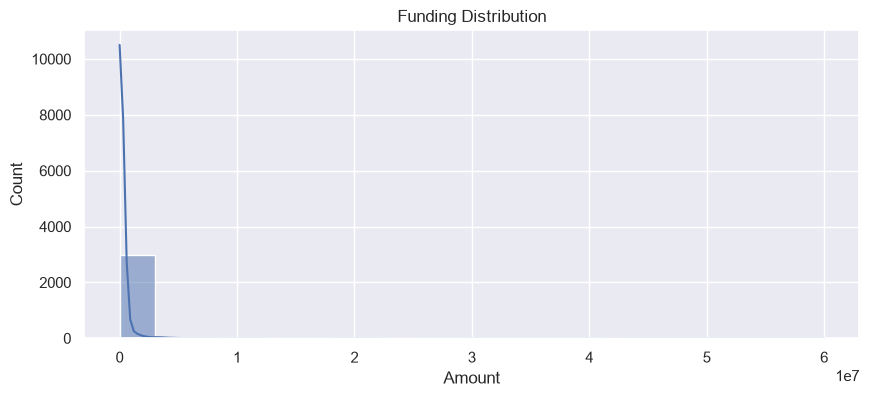

In [2]:
plt.figure(figsize=(10,4))

sns.set_theme(style="darkgrid")

sns.histplot(
    data=df,
    x='Amount',
    bins=20,
    kde=True
)

plt.title('Funding Distribution')

plt.savefig("Funding_Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight: 
###### I observe after seeing this chart Funding distribution is highly right-skewed. Most funding deals are concentrated in the lower funding range, while only a small number of deals involve very large funding amounts. This indicates that high-value funding deals are relatively rare compared with smaller funding deals.

#### Q2. create a chart which shows total deal counts based on time.

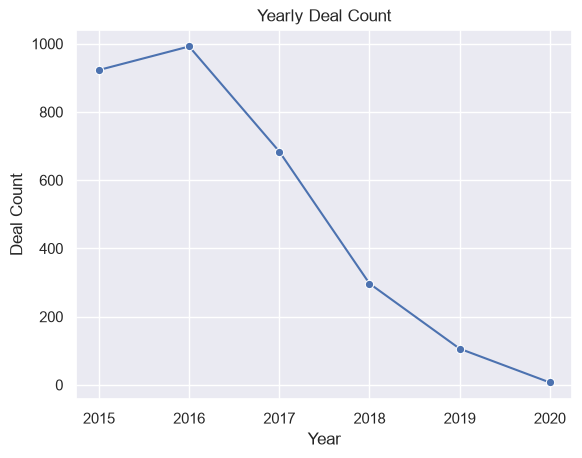

In [3]:
df['Date'] = pd.to_datetime(df['Date'])

df['Year'] = df['Date'].dt.year

time_wise_deal_count = df.groupby('Year')['Investment Type'].count()

sns.set_theme(style="darkgrid")

sns.lineplot(
    x=time_wise_deal_count.index,
    y=time_wise_deal_count.values,
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Deal Count')
plt.title('Yearly Deal Count')

plt.savefig("Yearly_Trend.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight:
###### This chart shows yearly deal count trend from 2015 to 2020. I observe 2015 ( 850+ ) to 2016 ( 1000 ) deal counts are increases after that deal count significantly decreases in 2020 deal count approax 0. this indicates starting year are deal counts very.

#### Q3. Create a chart which shows yearly amount trend.

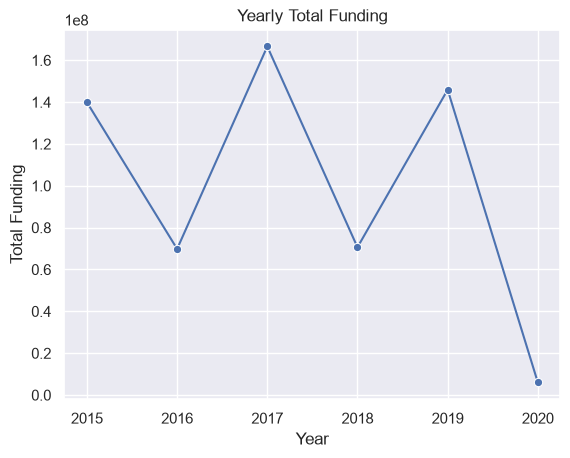

In [4]:
time_wise_funding_pattern = df.groupby('Year')['Amount'].sum()

sns.lineplot(
    x=time_wise_funding_pattern.index,
    y=time_wise_funding_pattern.values,
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Total Funding')
plt.title('Yearly Total Funding')

plt.savefig("Year_Wise_Deals_Trend.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight:
###### This chart shows amount increases and decreases in zig zag. in 2015 total funding (140M+) then 2016 amount decreases and amount save 65M+. after that 2017 amount increases and top amount is 160M+ then again amount drop in 2018 approx amount save same as first approax 65M+. then again amount increases in 2019 but not the top but approax 140M+ then again drop in 2020 and amount save approax 0. this indicates some deals are very high and other is small deals who increases mean. 

#### Q4. Top 5 city wise total funding.

In [ ]:
top_5_cities_funding = df.groupby('City  Location')['Amount'].sum().sort_values(ascending=False).head(5)

sns.barplot(
    x=top_5_cities_funding.index,
    y=top_5_cities_funding.values,
    hue=top_5_cities_funding.index
)

plt.title('Top 5 City wise Funding')
plt.xlabel('City')
plt.ylabel('Funding Amount')

plt.show()

#### Insight:
###### This chart shows Banglore city contributes highest in overall business approax (270M+) second is Mumbai approax (50M+). if i calculate add top 5 city amount into one so top 5 city contributes approax ~83.51% in overall Funding Amount. this indicates these top 5 city is the main city of our business. 

#### Q5. Create a chart which shows investment type wise deal count.

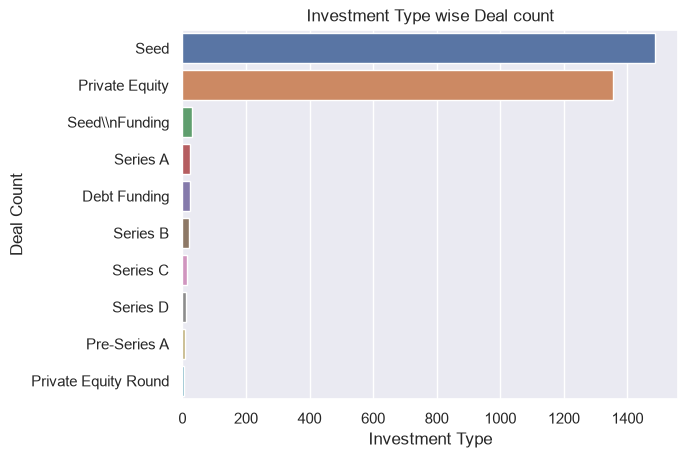

In [21]:
df['Investment Type'] = df['Investment Type'].replace({
    'Seed Funding': 'Seed',
    'Seed\\nFunding': 'Seed',
    'Seed / Angel Funding': 'Seed',
    'Seed/ Angel Funding': 'Seed',
    'Seed/Angel Funding': 'Seed',
    'Angel / Seed Funding': 'Seed',
    'Seed Round': 'Seed',
    'Seed / Angle Funding': 'Seed',
    'Angel Funding': 'Seed',
    'Angel Round': 'Seed',
    'Seed funding': 'Seed',
    'Angel': 'Seed',
    'Seed\\nFunding': 'Seed',
    'pre-series A': 'Pre-Series A',
    'Pre-series A': 'Pre-Series A',
    'pre-Series A': 'Pre-Series A',
    'Pre Series A': 'Pre-Series A',
    'Pre-Series A': 'Pre-Series A',
    'Crowd funding': 'Crowd Funding',
    'PrivateEquity': 'Private Equity',
    'Private\\nEquity': 'Private Equity',
    'Private': 'Private Equity',
    'Flipkart.com': 'Flipkart',
    'Ola Cabs': 'Ola'
})

investment_type_wise_deal_count = df.groupby('Investment Type')['Investment Type'].count().sort_values(ascending=False).head(10)

sns.barplot(
    x=investment_type_wise_deal_count.values,
    y=investment_type_wise_deal_count.index,
    hue=investment_type_wise_deal_count.index
)

plt.title('Investment Type wise Deal count')
plt.xlabel('Investment Type')
plt.ylabel('Deal Count')

plt.show()

#### Insight:
###### This chart shows only Seed and Private Equity have deal counts are very high and all Invwestment Type is make deal approax ~1. but Seed makes deal approax ~1400+ and Private Equity make approax ~1300+. This means only Seed and Private Equity make our startups business strong. 

#### Q6. Create a chart which shows top 10 city wise deal count.

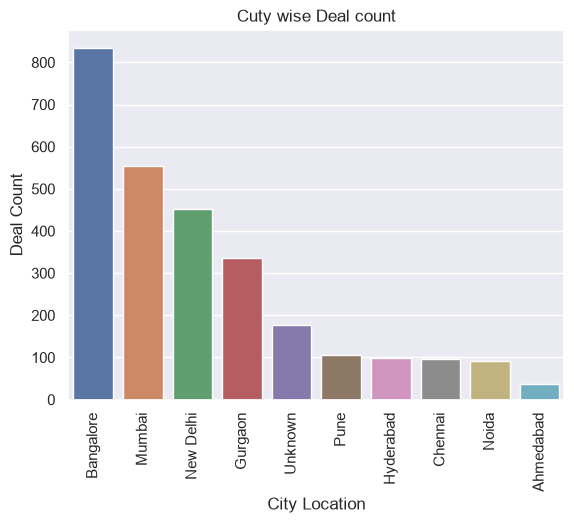

In [5]:
city_wise_deal_count = df.groupby('City  Location')['Investment Type'].count().sort_values(ascending=False).head(10)

sns.barplot(
    x=city_wise_deal_count.index,
    y=city_wise_deal_count.values,
    hue=city_wise_deal_count.index
)

plt.title('Cuty wise Deal count')
plt.xlabel('City Location')
plt.ylabel('Deal Count')
plt.xticks(rotation=90)

plt.savefig("Top_10_City_Wise_Deals.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight:
###### This chart shows Banglore have highest deal counts (~800+) as compared to other city and second is Mumbai (~550+) and 10th number is Ahmedabad (~30). I'm not sure but i think this charts shows Banglore city have highest deal counts maybe it is good for new startups but i can't conclude anything this is my thought.

#### Q7. Create a chart which shows top 10 startups total funding.

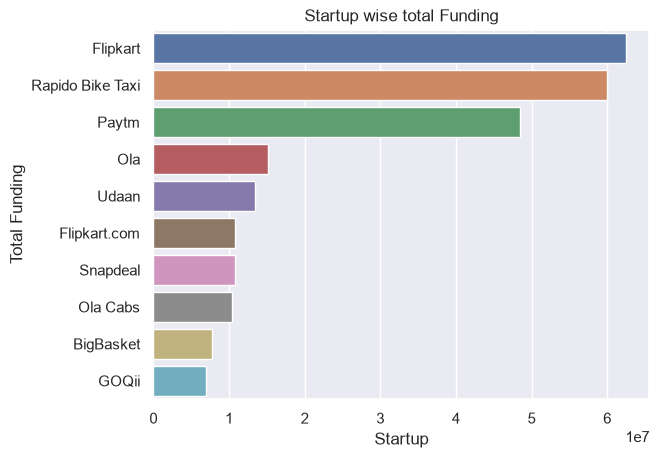

In [6]:
top_10_startups_total_funding=df.groupby('Startup Name')['Amount'].sum().sort_values(ascending=False).head(10)

sns.barplot(
    x=top_10_startups_total_funding.values,
    y=top_10_startups_total_funding.index,
    hue=top_10_startups_total_funding.index
)

plt.title('Startup wise total Funding')
plt.xlabel('Startup')
plt.ylabel('Total Funding')

plt.savefig("Top_10_startups_wise_Funding.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight:
###### This Chart shows Flipkart Startup total funding (~70M+) and second is Rapido Bike Taxi and its total funding is (~60M+). 3rd number is Paytm which total funding is (~45M+). This indicates old startups generate highest total funding in 2015 to 2020.

#### Q8. Create a chart which shows amount column have outliers or not?

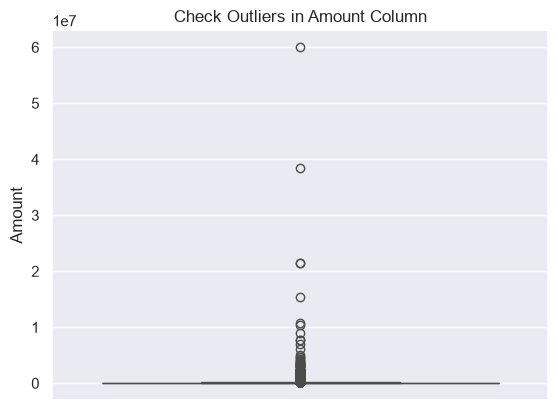

In [7]:
sns.boxplot(data=df, y='Amount')

plt.title('Check Outliers in Amount Column')

plt.savefig("Check_Outliers.png", dpi=300, bbox_inches="tight")

plt.show()

#### Insight:
###### This chart shows amount have high amount of outliers but we could not say remove outliers without checking it. maybe it is a high funding deals. one outlier point is ~60M so we can't say delete outliers immediately without checking.